# Aula 07 — Ciência de Dados
## Fundamentos de Mineração de Dados

**Curso:** Ciência de Dados | **Instituição:** Univassouras
**Prof. Mesc. Diego Ramos Inácio**

---

Este notebook é um guia prático da aula. Execute célula por célula com **Shift+Enter** e leia as explicações antes de cada bloco de código.

| Parte | Tema | Tópicos |
|-------|------|---------|
| 1 | Mineração de Dados | Pré-processamento, Classificação, Agrupamento, Regras de Associação |
| 2 | Coleta de Dados (REST + NoSQL) | Raspagem via API REST, MongoDB como destino dos dados brutos |
---

> **Bibliotecas necessárias:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `requests`, `pymongo`
> Instale com: `pip install numpy pandas matplotlib seaborn scikit-learn requests pymongo`
> A Parte 2 também exige um servidor **MongoDB** acessível em `mongodb://localhost:27017`.

> Esta aula é companheira da **Aula 08 — Ética, Governança e Qualidade de Dados**, que reaproveita o mesmo MongoDB sob um olhar diferente: não mais "como coletar", mas "o que esses dados coletados revelam sobre responsabilidade e governança".

In [1]:
# ── Imports usados em todo o notebook ──────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report

# semente para reprodutibilidade
np.random.seed(42)

print('Todas as bibliotecas carregadas com sucesso!')

Todas as bibliotecas carregadas com sucesso!


---
# PARTE 1 — Fundamentos de Mineração de Dados

## O que é Mineração de Dados?

**Mineração de Dados (Data Mining)** é o processo de descobrir padrões, anomalias e relações úteis em grandes volumes de dados.  
Pense nela como *garimpar ouro*: você peneira uma grande quantidade de material (dados brutos) para encontrar pepitas valiosas (insights).

### Principais tarefas de mineração:

| Tarefa | O que faz | Exemplo |
|--------|-----------|----------|
| **Classificação** | Prevê uma categoria para novos dados | Spam ou não-spam |
| **Agrupamento (Clustering)** | Agrupa dados similares sem rótulos | Segmentação de clientes |
| **Regressão** | Prevê um valor numérico | Preço de imóvel |
| **Regras de Associação** | Encontra itens que ocorrem juntos | Cesta de compras |
| **Detecção de Anomalia** | Identifica pontos fora do padrão | Fraude em cartão |

### Fluxo típico (KDD):

**KDD** é a sigla de *Knowledge Discovery in Databases* — em português, **"Descoberta de Conhecimento em Bancos de Dados"**. É o nome dado ao processo completo, do dado bruto até a informação útil:

```
Dados Brutos → Seleção → Pré-processamento → Transformação → Mineração → Interpretação
```

## 1.1 Pré-processamento — A base de tudo

Antes de qualquer algoritmo, os dados precisam estar limpos e no formato certo.  
**Regra de ouro:** *garbage in, garbage out* — dado ruim → resultado ruim.

### Etapas comuns:
- Tratar **valores ausentes** (NaN)
- Remover **duplicatas**
- **Codificar** variáveis categóricas em números
- **Normalizar/Escalar** variáveis numéricas

In [2]:
# ── Criando um dataset de exemplo: clientes de uma loja ────────────────────
dados_brutos = pd.DataFrame({
    'cliente_id': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 10],  # 10 duplicado!
    'idade':      [25, None, 35, 45, 28, 60, None, 33, 41, 55, 55],
    'renda_mensal': [2500, 4000, None, 8000, 3200, 6500, 2800, None, 5100, 9000, 9000],
    'categoria':  ['bronze', 'prata', 'ouro', 'ouro', 'bronze', 'diamante',
                   'bronze', 'prata', 'prata', 'diamante', 'diamante'],
    'comprou_novamente': ['sim', 'não', 'sim', 'sim', 'não', 'sim', 'não', 'sim', 'sim', 'sim', 'sim']
})

print('=== Dataset original (com problemas) ===')
print(f'\nFormato: {dados_brutos.shape[0]} linhas x {dados_brutos.shape[1]} colunas')
print(f'\nValores ausentes por coluna:')
print(dados_brutos.isnull().sum())

dados_brutos

=== Dataset original (com problemas) ===

Formato: 11 linhas x 5 colunas

Valores ausentes por coluna:
cliente_id           0
idade                2
renda_mensal         2
categoria            0
comprou_novamente    0
dtype: int64


,cliente_id,idade,renda_mensal,categoria,comprou_novamente
0,1,25.0,2500.0,bronze,sim
1,2,NaN,4000.0,prata,não
2,3,35.0,NaN,ouro,sim
3,4,45.0,8000.0,ouro,sim
4,5,28.0,3200.0,bronze,não
5,6,60.0,6500.0,diamante,sim
6,7,NaN,2800.0,bronze,não
7,8,33.0,NaN,prata,sim
8,9,41.0,5100.0,prata,sim
9,10,55.0,9000.0,diamante,sim


In [3]:
# ── Limpando os dados passo a passo ────────────────────────────────────────

# 1. Remover duplicatas
df = dados_brutos.drop_duplicates(subset='cliente_id')
print(f'Após remover duplicatas: {len(df)} linhas')

# 2. Preencher valores ausentes com a mediana (mais robusto que a média)
df['idade'] = df['idade'].fillna(df['idade'].median())
df['renda_mensal'] = df['renda_mensal'].fillna(df['renda_mensal'].median())
print(f'Valores ausentes restantes: {df.isnull().sum().sum()}')

# 3. Codificar variáveis categóricas
le_cat = LabelEncoder()
le_alvo = LabelEncoder()

df['categoria_cod'] = le_cat.fit_transform(df['categoria'])
df['alvo'] = le_alvo.fit_transform(df['comprou_novamente'])  # sim=1, nao=0

print('\nCodificação de "categoria":', dict(zip(le_cat.classes_, le_cat.transform(le_cat.classes_))))
print('Codificação de "comprou_novamente":', dict(zip(le_alvo.classes_, le_alvo.transform(le_alvo.classes_))))

print('\n=== Dataset limpo e codificado ===')
print(df[['cliente_id','idade','renda_mensal','categoria','categoria_cod','comprou_novamente','alvo']])

Após remover duplicatas: 10 linhas
Valores ausentes restantes: 0

Codificação de "categoria": {'bronze': np.int64(0), 'diamante': np.int64(1), 'ouro': np.int64(2), 'prata': np.int64(3)}
Codificação de "comprou_novamente": {'não': np.int64(0), 'sim': np.int64(1)}

=== Dataset limpo e codificado ===
   cliente_id  idade  renda_mensal categoria  categoria_cod comprou_novamente  \
0           1   25.0        2500.0    bronze              0               sim   
1           2   38.0        4000.0     prata              3               não   
2           3   35.0        4550.0      ouro              2               sim   
3           4   45.0        8000.0      ouro              2               sim   
4           5   28.0        3200.0    bronze              0               não   
5           6   60.0        6500.0  diamante              1               sim   
6           7   38.0        2800.0    bronze              0               não   
7           8   33.0        4550.0     prata         

## 1.2 Classificação — Árvore de Decisão

A **Árvore de Decisão** é um dos algoritmos mais intuitivos: ela aprende regras do tipo *se-então* a partir dos dados.

**Exemplo:** "Se renda > R$5.000 E categoria = ouro → provavelmente compra novamente"

**Passos:**
1. Separar **features (X)** — as variáveis de entrada/preditoras usadas para prever algo (ex.: idade, renda) — do **alvo (y)** — a variável que queremos prever (ex.: "comprou novamente?"). `X` e `y` são apenas os nomes que a comunidade de Machine Learning convencionou usar para essas duas partes.
2. Dividir em treino (80%) e teste (20%)
3. Treinar o modelo
4. Avaliar com as métricas certas

In [4]:
# ── Gerando um dataset maior para classificação (mais realista) ────────────
n = 200
idades = np.random.randint(18, 70, n)
rendas = np.random.randint(1500, 15000, n)
# regra artificial: renda alta + jovem/adulto → tende a comprar novamente
alvo = ((rendas > 5000) & (idades < 50)).astype(int)
# adiciona um pouco de ruído para não ser perfeito
# p=[0.85, 0.15] -> probabilidade de cada opção: 85% de chance de sortear 0 (sem ruído),
# 15% de chance de sortear 1 (inverte o alvo, simulando um erro/exceção real)
ruido = np.random.choice([0, 1], n, p=[0.85, 0.15])
alvo = np.abs(alvo - ruido).clip(0, 1)

df_class = pd.DataFrame({'idade': idades, 'renda': rendas, 'comprou': alvo})
print(f'Dataset de classificação: {len(df_class)} registros')
print(f'Distribuição do alvo: {df_class["comprou"].value_counts().to_dict()}  (0=não, 1=sim)')

# ── Separar X (features) e y (alvo) ────────────────────────────────────────
X = df_class[['idade', 'renda']]
y = df_class['comprou']

# random_state=42 funciona como a "semente" (np.random.seed) de cima, mas local
# a esta função: garante que a divisão treino/teste seja sempre a mesma a cada
# execução, em vez de sortear linhas diferentes toda vez.
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'\nTreino: {len(X_treino)} amostras | Teste: {len(X_teste)} amostras')

Dataset de classificação: 200 registros
Distribuição do alvo: {0: 101, 1: 99}  (0=não, 1=sim)

Treino: 160 amostras | Teste: 40 amostras


Acurácia no conjunto de teste: 82.50%

Relatório detalhado:
              precision    recall  f1-score   support

 Não comprou       0.84      0.80      0.82        20
     Comprou       0.81      0.85      0.83        20

    accuracy                           0.82        40
   macro avg       0.83      0.82      0.82        40
weighted avg       0.83      0.82      0.82        40

Como ler as colunas do relatório acima:
  precision (precisão) -> das vezes que o modelo previu essa classe, quantas estavam certas
  recall (revocação)   -> dos casos reais dessa classe, quantos o modelo conseguiu encontrar
  f1-score             -> média que equilibra precision e recall em um único número (0 a 1)
  support              -> quantos exemplos reais dessa classe existem no conjunto de teste


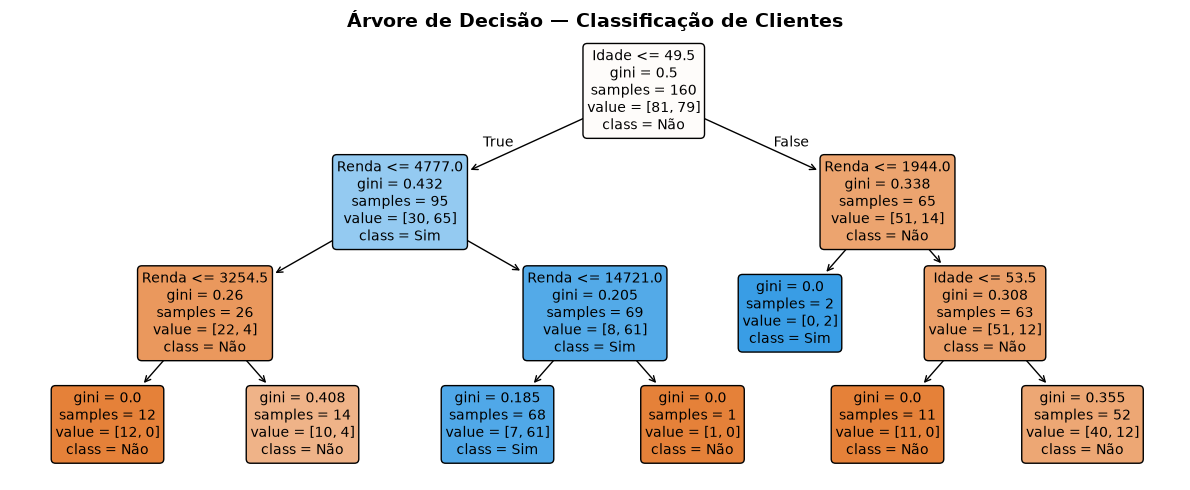


Interpretação: cada nó mostra a regra de decisão e a "pureza" do grupo,
medida pelo índice de Gini (0 = nó 100% puro, só uma classe; quanto maior,
mais misturadas estão as classes "Não"/"Sim" naquele nó).


In [5]:
# ── Treinar e avaliar a Árvore de Decisão ──────────────────────────────────
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_treino, y_treino)

y_pred = modelo.predict(X_teste)
acc = accuracy_score(y_teste, y_pred)

print(f'Acurácia no conjunto de teste: {acc:.2%}')
print('\nRelatório detalhado:')
print(classification_report(y_teste, y_pred, target_names=['Não comprou', 'Comprou']))

print('Como ler as colunas do relatório acima:')
print('  precision (precisão) -> das vezes que o modelo previu essa classe, quantas estavam certas')
print('  recall (revocação)   -> dos casos reais dessa classe, quantos o modelo conseguiu encontrar')
print('  f1-score             -> média que equilibra precision e recall em um único número (0 a 1)')
print('  support              -> quantos exemplos reais dessa classe existem no conjunto de teste')

# ── Visualizar a árvore ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(modelo, feature_names=['Idade', 'Renda'], class_names=['Não', 'Sim'],
          filled=True, rounded=True, ax=ax)
ax.set_title('Árvore de Decisão — Classificação de Clientes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nInterpretação: cada nó mostra a regra de decisão e a "pureza" do grupo,')
print('medida pelo índice de Gini (0 = nó 100% puro, só uma classe; quanto maior,')
print('mais misturadas estão as classes "Não"/"Sim" naquele nó).')

## 1.3 Agrupamento — K-Means

**Clustering** é uma técnica *não supervisionada*: não há rótulos, o algoritmo descobre grupos sozinho.

**K-Means** funciona assim:
1. Escolhe K centros aleatórios
2. Atribui cada ponto ao centro mais próximo
3. Recalcula os centros como médias dos grupos
4. Repete até estabilizar

**Aplicação clássica:** segmentação de clientes por comportamento de compra.

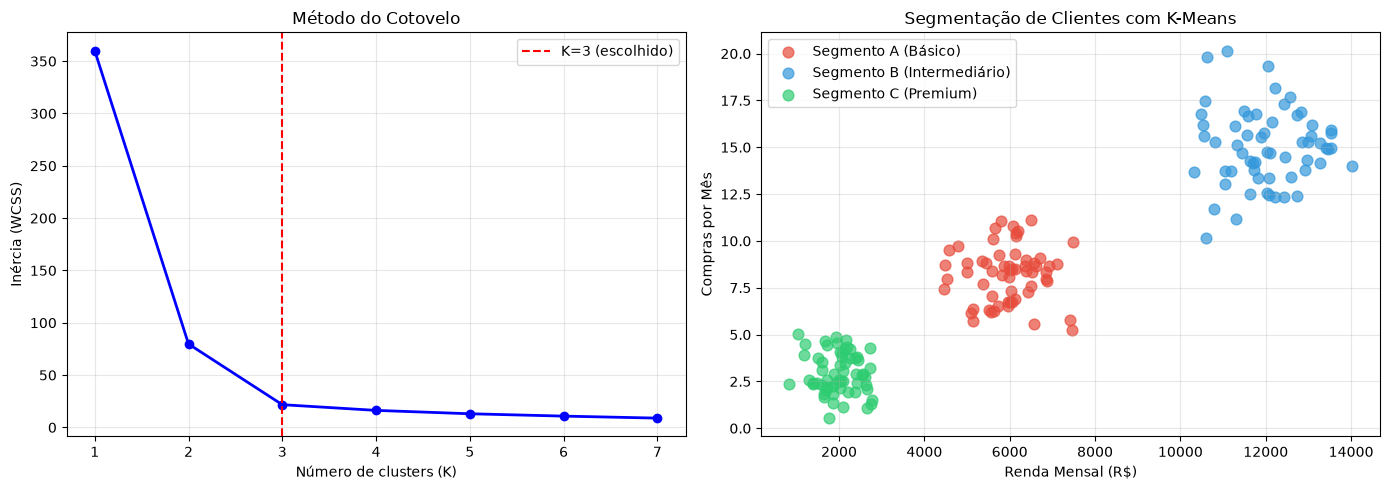

Distribuição por segmento:
segmento
Segmento C (Premium)          60
Segmento A (Básico)           60
Segmento B (Intermediário)    60
Name: count, dtype: int64


In [6]:
# ── Gerando dados de clientes para segmentação ─────────────────────────────
# 3 perfis bem definidos
g1 = np.random.multivariate_normal([2000, 3],  [[200000, 0], [0, 1]], 60)   # baixa renda, baixa frequência de compra
g2 = np.random.multivariate_normal([6000, 8],  [[500000, 0], [0, 2]], 60)   # média renda, média frequência de compra
g3 = np.random.multivariate_normal([12000, 15], [[800000, 0], [0, 3]], 60)  # alta renda, alta frequência de compra

dados_seg = pd.DataFrame(
    np.vstack([g1, g2, g3]),
    columns=['renda_mensal', 'compras_mes']
).clip(lower=0)  # sem valores negativos

# ── Escalar antes do K-Means (importante!) ─────────────────────────────────
# Sem escalar, a renda (valores na casa dos milhares) dominaria o cálculo de
# distância sobre compras_mes (valores de 0 a ~20), distorcendo os clusters.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(dados_seg)

# ── Método do cotovelo para escolher K ─────────────────────────────────────
# K é o número de clusters (grupos) que pedimos ao algoritmo para formar.
# n_init=10 -> roda o K-Means 10 vezes com pontos de partida aleatórios diferentes
# e mantém o melhor resultado (evita ficar preso em uma divisão ruim por azar no sorteio inicial).
inercias = []
ks = range(1, 8)
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico do cotovelo
# Inércia = WCSS (Within-Cluster Sum of Squares, "soma dos quadrados das distâncias
# dentro de cada cluster"): mede o quão perto os pontos estão do centro do seu grupo.
# Quanto mais clusters (K), menor a inércia — mas em algum ponto o ganho fica pequeno;
# esse ponto de "quebra" na curva (o cotovelo) é o K escolhido.
axes[0].plot(ks, inercias, 'bo-', linewidth=2)
axes[0].axvline(x=3, color='red', linestyle='--', label='K=3 (escolhido)')
axes[0].set_xlabel('Número de clusters (K)')
axes[0].set_ylabel('Inércia (WCSS)')
axes[0].set_title('Método do Cotovelo')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Clusterização final com K=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
dados_seg['segmento'] = kmeans.fit_predict(X_scaled)

cores = {0: '#e74c3c', 1: '#3498db', 2: '#2ecc71'}
rotulos = {0: 'Segmento A (Básico)', 1: 'Segmento B (Intermediário)', 2: 'Segmento C (Premium)'}

for seg in [0, 1, 2]:
    mask = dados_seg['segmento'] == seg
    axes[1].scatter(dados_seg.loc[mask, 'renda_mensal'],
                    dados_seg.loc[mask, 'compras_mes'],
                    c=cores[seg], label=rotulos[seg], alpha=0.7, s=60)

axes[1].set_xlabel('Renda Mensal (R$)')
axes[1].set_ylabel('Compras por Mês')
axes[1].set_title('Segmentação de Clientes com K-Means')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Distribuição por segmento:')
print(dados_seg['segmento'].value_counts().rename(rotulos))

## 1.4 Regras de Associação — Análise de Cesta de Compras

**Regras de Associação** buscam padrões do tipo: *"quem compra X também compra Y"*, em que **X e Y são itens** (produtos) que aparecem juntos em transações (cestas de compra) — por exemplo, X = "pão" e Y = "manteiga".

O algoritmo mais famoso é o **Apriori**: ele percorre as transações contando quais itens (e quais pares de itens) aparecem juntos com mais frequência, para depois calcular as métricas abaixo.

### Métricas fundamentais:

Antes das fórmulas, as abreviações usadas:
- **N** = número total de transações (cestas de compra) na base
- **frq(X)** = frequência de X = em quantas transações o item X aparece
- **frq(X,Y)** = frequência conjunta = em quantas transações X **e** Y aparecem juntos
- **conf(X→Y)** = confiança da regra "quem compra X compra Y" (ver linha "Confiança" abaixo)
- **probabilidade** = chance estimada de algo acontecer, calculada aqui como uma proporção (nº de casos favoráveis ÷ nº total de casos)

| Métrica | Fórmula | Significado |
|---------|---------|-------------|
| **Suporte** | frq(X,Y) / N | Com que frequência X e Y aparecem juntos, em relação a todas as transações |
| **Confiança** | frq(X,Y) / frq(X) | Entre as transações que já têm X, qual a **probabilidade** de também terem Y? |
| **Lift** | conf(X→Y) / suporte(Y) | Compara a confiança observada com o que seria esperado se X e Y fossem independentes. Lift > 1 = associação real (não é coincidência) |

Abaixo, implementamos o conceito manualmente para entender a lógica:

In [7]:
# ── Dataset de transações (cesta de compras) ───────────────────────────────
transacoes = [
    ['pão', 'leite', 'manteiga'],
    ['pão', 'leite'],
    ['pão', 'frango', 'leite', 'manteiga'],
    ['frango', 'queijo'],
    ['pão', 'manteiga'],
    ['leite', 'queijo'],
    ['pão', 'leite', 'queijo'],
    ['pão', 'frango'],
    ['leite', 'manteiga', 'queijo'],
    ['pão', 'leite', 'frango', 'queijo']
]

N = len(transacoes)  # N = número total de transações
print(f'Total de transações: {N}\n')

# ── Calcular suporte de pares de itens ─────────────────────────────────────
from itertools import combinations

# conta frequência individual: quantas transações contêm cada item
freq_item = {}
for t in transacoes:
    for item in t:
        freq_item[item] = freq_item.get(item, 0) + 1

# conta frequência de pares: quantas transações contêm cada par de itens juntos
freq_par = {}
for t in transacoes:
    for par in combinations(sorted(set(t)), 2):
        freq_par[par] = freq_par.get(par, 0) + 1

# calcula métricas
print(f'{"Regra":<30} {"Suporte":>10} {"Confiança":>12} {"Lift":>8}')
print('-' * 65)

regras = []
for (a, b), freq in sorted(freq_par.items(), key=lambda x: -x[1]):
    suporte  = freq / N
    conf_ab  = freq / freq_item[a]   # P(B|A): probabilidade de B ocorrer, dado que A já ocorreu
    conf_ba  = freq / freq_item[b]   # P(A|B): probabilidade de A ocorrer, dado que B já ocorreu
    lift     = conf_ab / (freq_item[b] / N)

    if suporte >= 0.3:  # filtro mínimo de suporte
        regras.append({'regra': f'{a} → {b}', 'suporte': suporte,
                       'confianca': conf_ab, 'lift': lift})
        print(f'{a + " → " + b:<30} {suporte:>10.2f} {conf_ab:>12.2f} {lift:>8.2f}')

print(f'\nLift > 1 = associação genuína. Lift = 1 = independência. Lift < 1 = relação negativa.')

Total de transações: 10

Regra                             Suporte    Confiança     Lift
-----------------------------------------------------------------
leite → pão                          0.50         0.71     1.02
leite → queijo                       0.40         0.57     1.14
leite → manteiga                     0.30         0.43     1.07
manteiga → pão                       0.30         0.75     1.07
frango → pão                         0.30         0.75     1.07

Lift > 1 = associação genuína. Lift = 1 = independência. Lift < 1 = relação negativa.


---
# PARTE 2 — Coleta de Dados Externos: Raspagem via REST + MongoDB

O fluxo KDD (Seleção → Pré-processamento → Transformação → Mineração → Interpretação) começa pela **coleta** dos dados brutos — e, na prática, boa parte dos datasets de mineração de dados não chega pronta em um CSV. Eles vêm de **raspagem de APIs REST**, scraping de sites, sensores, logs etc., quase sempre em **JSON**.

Siglas usadas nesta parte:
- **API** (*Application Programming Interface*, "Interface de Programação de Aplicações") — o "cardápio" de operações que um sistema externo expõe para outros programas conversarem com ele.
- **REST** (*Representational State Transfer*) — um estilo de API muito comum, que usa endereços web (URLs) e verbos HTTP como `GET` (buscar/ler) e `POST` (criar) para trocar dados.
- **JSON** (*JavaScript Object Notation*) — um formato de texto para representar dados estruturados, muito parecido com um dicionário Python: `{"chave": "valor"}`.
- **SQL** (*Structured Query Language*) — a linguagem usada para consultar bancos de dados relacionais (tabelas).
- **NoSQL** — qualquer banco de dados que **não** segue o modelo de tabelas do SQL; o MongoDB é um exemplo orientado a **documentos**.
- **BSON** (*Binary JSON*) — o formato binário que o MongoDB usa internamente para guardar cada documento; na prática, você só manipula JSON/dicionários Python, e o MongoDB cuida da conversão.

Um banco NoSQL orientado a documentos, como o **MongoDB**, foi pensado exatamente para receber esse tipo de dado semi-estruturado sem exigir um esquema de tabelas definido antes de começar a coletar.

```
Raspagem / API REST (JSON)  ──►  MongoDB (documentos)  ──►  Pandas (DataFrame)  ──►  Mineração (Parte 1)
```

| Banco Relacional (SQL) | Banco NoSQL (MongoDB) |
|---|---|
| Tabelas com colunas fixas | Coleções de **documentos** (JSON/BSON) |
| Exige esquema definido antes de inserir dados | Esquema flexível — cada documento pode ter campos diferentes |
| Bom para dados tabulares e transacionais | Bom para dados semi-estruturados vindos de raspagem/APIs |

> **Objetivo desta parte:** simular, de ponta a ponta, a coleta de dados de uma fonte externa (raspagem via REST) até deixá-los prontos, em um DataFrame, para as técnicas de mineração vistas na Parte 1.

> **Pré-requisito:** um servidor MongoDB rodando localmente (`mongodb://localhost:27017`).  
> Instale as libs desta parte com `pip install requests pymongo`.

In [8]:
# ── Bibliotecas desta parte: requests (chamadas REST) e pymongo (MongoDB) ──
import requests
from pymongo import MongoClient

# Conecta ao servidor MongoDB local.
# OBS: esta linha NÃO falha mesmo se não houver MongoDB rodando — o pymongo só
# tenta de fato abrir a conexão quando fazemos a primeira operação no banco
# (por isso o erro, se houver, só aparece mais abaixo, no insert_many).
cliente_mongo = MongoClient('mongodb://localhost:27017')

# 'db'   -> o banco de dados (equivalente a um "schema")
# 'col'  -> a coleção dentro do banco (equivalente a uma "tabela")
db = cliente_mongo['aula0708_mineracao']
colecao_usuarios = db['usuarios_api']

print('Cliente MongoDB criado.')
print('Banco:    aula0708_mineracao')
print('Coleção:  usuarios_api')

Cliente MongoDB criado.
Banco:    aula0708_mineracao
Coleção:  usuarios_api


## 2.1 Passo 1 — "Raspar" uma base de teste conhecida via REST

Vamos simular uma raspagem de dados usando a **JSONPlaceholder** (`https://jsonplaceholder.typicode.com`): uma API REST pública, gratuita e muito conhecida entre desenvolvedores justamente para **testes e prototipagem** — não exige chave de acesso e sempre devolve o mesmo conjunto fixo de dados fictícios de usuários.

Isso representa, em miniatura, o que acontece numa raspagem real: um sistema externo expõe dados (via REST, scraping de HTML, etc.), e o primeiro trabalho de quem vai minerar esses dados é buscá-los e guardá-los de forma confiável antes de qualquer pré-processamento.

In [9]:
# ── Requisição GET para a API de teste (JSONPlaceholder) ──────────────────
# GET é o verbo HTTP que significa "buscar/ler dados" (sem alterar nada no servidor)
url = 'https://jsonplaceholder.typicode.com/users'
resposta = requests.get(url, timeout=10)

# Boa prática: sempre verificar se a requisição deu certo antes de usar o resultado.
# status_code é o código numérico de resposta HTTP: 200 significa "OK, sucesso".
# resposta.ok é True para qualquer código entre 200 e 299 (a faixa "2xx" = sucesso).
print(f'Status da requisição: {resposta.status_code} ({"OK" if resposta.ok else "ERRO"})')

# .json() converte o corpo da resposta (texto em formato JSON) em estruturas Python (lista de dicts)
usuarios_json = resposta.json()
print(f'Total de registros recebidos: {len(usuarios_json)}')

# ── Dando uma espiada no formato de UM documento ───────────────────────────
print('\nExemplo de um registro (note os campos aninhados "address" e "company"):')
usuarios_json[0]

Status da requisição: 200 (OK)
Total de registros recebidos: 10

Exemplo de um registro (note os campos aninhados "address" e "company"):


{'id': 1,
 'name': 'Leanne Graham',
 'username': 'Bret',
 'email': 'Sincere@april.biz',
 'address': {'street': 'Kulas Light',
  'suite': 'Apt. 556',
  'city': 'Gwenborough',
  'zipcode': '92998-3874',
  'geo': {'lat': '-37.3159', 'lng': '81.1496'}},
 'phone': '1-770-736-8031 x56442',
 'website': 'hildegard.org',
 'company': {'name': 'Romaguera-Crona',
  'catchPhrase': 'Multi-layered client-server neural-net',
  'bs': 'harness real-time e-markets'}}

## 2.2 Passo 2 — Levar os dados raspados para o MongoDB

Aqui está o ponto-chave do NoSQL orientado a documentos: o JSON que veio da raspagem **não precisa ser "achatado" em colunas** antes de salvar. Cada usuário — com seus campos aninhados (`address`, `company`, etc.) — vira **um documento** na coleção, exatamente como chegou da fonte externa. Em um banco relacional, isso normalmente exigiria quebrar os dados em várias tabelas (usuários, endereços, empresas) ligadas por chaves estrangeiras antes mesmo de poder gravar.

In [10]:
# ── Limpa a coleção antes de inserir, para o notebook poder ser reexecutado
#    do zero sem duplicar documentos ────────────────────────────────────────
colecao_usuarios.delete_many({})

# ── insert_many: grava toda a lista de documentos JSON de uma só vez ───────
# (cada item da lista "usuarios_json" se torna um documento na coleção)
resultado = colecao_usuarios.insert_many(usuarios_json)

print(f'Documentos inseridos agora: {len(resultado.inserted_ids)}')
print(f'Total de documentos na coleção: {colecao_usuarios.count_documents({})}')

# ── Confirmando que a estrutura aninhada foi preservada no MongoDB ────────
# find_one busca um único documento; {'_id': 0} oculta o id interno do Mongo
doc_exemplo = colecao_usuarios.find_one({}, {'_id': 0})
print('\nDocumento salvo no MongoDB (estrutura JSON original preservada):')
doc_exemplo

Documentos inseridos agora: 10
Total de documentos na coleção: 10

Documento salvo no MongoDB (estrutura JSON original preservada):


{'id': 1,
 'name': 'Leanne Graham',
 'username': 'Bret',
 'email': 'Sincere@april.biz',
 'address': {'street': 'Kulas Light',
  'suite': 'Apt. 556',
  'city': 'Gwenborough',
  'zipcode': '92998-3874',
  'geo': {'lat': '-37.3159', 'lng': '81.1496'}},
 'phone': '1-770-736-8031 x56442',
 'website': 'hildegard.org',
 'company': {'name': 'Romaguera-Crona',
  'catchPhrase': 'Multi-layered client-server neural-net',
  'bs': 'harness real-time e-markets'}}

## 2.3 Passo 3 — Consultar os dados raspados e preparar para a mineração

Com os dados já no banco, podemos fazer consultas (`find`) com filtros e operadores, inclusive em campos aninhados, usando a notação `"campo.subcampo"`. Ao final, trazemos o resultado de volta para um `DataFrame`, fechando o ciclo **raspagem (REST) → MongoDB → Pandas**, pronto para as técnicas da Parte 1 (pré-processamento, classificação, clustering, associação).

In [11]:
print('=== 1. Nome e cidade de todos os usuários ===')
# projeção {'name': 1, 'address.city': 1, '_id': 0} -> só devolve esses campos
for u in colecao_usuarios.find({}, {'name': 1, 'address.city': 1, '_id': 0}):
    print(f"  {u['name']:<20} — {u['address']['city']}")

print('\n=== 2. Usuários cuja empresa tem "catchPhrase" com a palavra "synergies" ===')
# $regex busca por padrão de texto; $options: 'i' = sem diferenciar maiúsc./minúsc.
filtro = {'company.catchPhrase': {'$regex': 'synergies', '$options': 'i'}}
for u in colecao_usuarios.find(filtro, {'name': 1, 'company.name': 1, '_id': 0}):
    print(f"  {u['name']:<20} — empresa: {u['company']['name']}")

print('\n=== 3. Quantos usuários têm website cadastrado ===')
# $exists verifica se o campo existe; $ne ("not equal", diferente de) descarta strings vazias
total_com_site = colecao_usuarios.count_documents({'website': {'$exists': True, '$ne': ''}})
print(f'  {total_com_site} de {colecao_usuarios.count_documents({})} usuários têm website')

print('\n=== 4. Trazendo os dados de volta para o Pandas ===')
# find(...) não devolve a lista pronta: devolve um "cursor", um ponteiro que percorre
# os resultados aos poucos (sem carregar tudo de uma vez na memória). list(...) percorre
# esse cursor inteiro e materializa o resultado como uma lista comum de dicionários.
docs = list(colecao_usuarios.find(
    {}, {'_id': 0, 'name': 1, 'username': 1, 'email': 1, 'company.name': 1}
))
# pd.json_normalize "achata" os campos aninhados (ex.: company.name) em colunas
df_usuarios = pd.json_normalize(docs)
print(df_usuarios)

=== 1. Nome e cidade de todos os usuários ===
  Leanne Graham        — Gwenborough
  Ervin Howell         — Wisokyburgh
  Clementine Bauch     — McKenziehaven
  Patricia Lebsack     — South Elvis
  Chelsey Dietrich     — Roscoeview
  Mrs. Dennis Schulist — South Christy
  Kurtis Weissnat      — Howemouth
  Nicholas Runolfsdottir V — Aliyaview
  Glenna Reichert      — Bartholomebury
  Clementina DuBuque   — Lebsackbury

=== 2. Usuários cuja empresa tem "catchPhrase" com a palavra "synergies" ===

=== 3. Quantos usuários têm website cadastrado ===
  10 de 10 usuários têm website

=== 4. Trazendo os dados de volta para o Pandas ===
                       name          username                      email  \
0             Leanne Graham              Bret          Sincere@april.biz   
1              Ervin Howell         Antonette          Shanna@melissa.tv   
2          Clementine Bauch          Samantha         Nathan@yesenia.net   
3          Patricia Lebsack          Karianne  Julianne.OCo

## 2.4 Resumo do fluxo de coleta

```
Raspagem / GET /users (REST, JSON)
      │
      ▼
requests.get(...).json()        ← dados chegam como lista de dicionários Python
      │
      ▼
colecao.insert_many(...)        ← cada dicionário se torna um documento no MongoDB
      │
      ▼
colecao.find(...)               ← consultas com filtros, inclusive em campos aninhados
      │
      ▼
pd.json_normalize(...)          ← volta para DataFrame, pronto para a Parte 1 (mineração)
```

> **Para fixar:** raspar dados de uma API/site é só o primeiro passo. O que vem depois — limpar, codificar, escalar, minerar (Parte 1) — é o que transforma dado bruto em informação útil.

> **Continua na Aula 08:** os mesmos documentos que acabamos de gravar no MongoDB serão reaproveitados lá para discutir **governança de dados** — o que foi coletado, com que base legal, e os riscos do esquema flexível do NoSQL.

---
# Resumo da Aula 07

## Parte 1 — Mineração de Dados

| Conceito | O que aprendemos |
|----------|------------------|
| **KDD** | Processo: seleção → pré-processamento → transformação → mineração → interpretação |
| **Pré-processamento** | Tratar nulos, duplicatas, codificar categorias, escalar features |
| **Classificação** | Árvore de Decisão aprende regras se-então a partir dos dados rotulados |
| **Clustering** | K-Means agrupa dados similares sem rótulos; cotovelo para escolher K |
| **Associação** | Suporte, Confiança, Lift — quem compra X também compra Y |

## Parte 2 — Coleta de Dados (REST + MongoDB)

| Conceito | O que aprendemos |
|----------|------------------|
| **Raspagem/REST** | `requests.get(...).json()` como fonte real de dados de mineração |
| **NoSQL (MongoDB)** | Documentos JSON gravados sem precisar achatar em tabelas |
| **Consulta** | `find`, filtros, inclusive em campos aninhados |
| **Volta ao Pandas** | `pd.json_normalize()` prepara os dados coletados para a Parte 1 |

---
> **Próxima aula:** Ética, Governança e Qualidade de Dados — vamos olhar para os mesmos dados coletados aqui sob a ótica de responsabilidade e riscos.

**Prof. Mesc. Diego Ramos Inácio | Univassouras 2026.1**